# Exploración del dataset LSC5 (equipo Colombia)

Fase 1: estudio del dataset. Una sección por tarea:

1. Forma de los `.npy`, longitud de las secuencias y pares video–landmarks
2. Porcentaje de frames sin mano detectada (ceros) por participante y por vista
3. Mano dominante de cada participante
4. Las 5 señas y qué partes del cuerpo usa cada una
5. Hallazgos y recomendaciones de preprocesamiento

In [3]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Rutas relativas a notebooks/: el proyecto guarda los datos en data/train (y data/test cuando se publique).
# Los videos (.mp4) son opcionales: solo se usan en la sección 4.5 (fotogramas).
DATOS = Path("../data")
TRAIN = DATOS / "train"
TEST = DATOS / "test"

PATRON = re.compile(r"S(\d+)_M(\d+)_V(\d+)_C(\d+)_Clip(\d+)", re.I)
print("Existe train:", TRAIN.exists(), ". Existe test:", TEST.exists(),
      ". Hay videos de train:", (TRAIN / "videos").exists())

Existe train: True . Existe test: True


## 1. Forma de los .npy, longitud de secuencias y pares video–landmarks

### 1.1 Conteo de archivos

In [5]:
lm_train = sorted((TRAIN / "landmarks").rglob("*.npy"))
vd_train = sorted((TRAIN / "videos").rglob("*.mp4"))
lm_test = sorted((TEST / "landmarks").rglob("*.npy"))
vd_test = sorted((TEST / "videos").rglob("*.mp4"))

print(f"train: {len(lm_train)} landmarks - {len(vd_train)} videos   (esperado 1125 - 1125)")
print(f"test : {len(lm_test)} landmarks - {len(vd_test)} videos   (esperado 375 - 375)")

train: 1125 landmarks - 1125 videos   (esperado 1125 - 1125)
test : 375 landmarks - 375 videos   (esperado 375 - 375)


### 1.2 Inspección de cada archivo

In [8]:
def inspeccionar(ruta):
    r = {"archivo": ruta.name, "clase": ruta.parent.name}
    m = PATRON.search(ruta.stem)
    if m:
        r.update(sena=f"S{m[1]}", participante=f"M{m[2]}", vista=f"V{m[3]}", camara=f"C{m[4]}")
    try:
        x = np.load(ruta, allow_pickle=False)
    except Exception as e:
        r["error"] = str(e)
        return r
    r.update(ndim=x.ndim, shape=str(x.shape), dtype=str(x.dtype))
    if x.ndim == 2:
        r["frames"], r["features"] = x.shape
    r["tiene_nan"] = bool(np.isnan(x).any())
    r["todo_cero"] = bool((x == 0).all())
    return r

df_train = pd.DataFrame([inspeccionar(p) for p in lm_train])
df_test = pd.DataFrame([inspeccionar(p) for p in lm_test])
df_train.head(200)

,archivo,clase,sena,participante,vista,camara,ndim,shape,dtype,frames,features,tiene_nan,todo_cero
0,S01_M02_V01_C01_Clip076.npy,sign_01,S01,M02,V01,C01,2,"(62, 1662)",float64,62,1662,False,False
1,S01_M02_V01_C01_Clip077.npy,sign_01,S01,M02,V01,C01,2,"(83, 1662)",float64,83,1662,False,False
2,S01_M02_V01_C01_Clip078.npy,sign_01,S01,M02,V01,C01,2,"(78, 1662)",float64,78,1662,False,False
3,S01_M02_V01_C01_Clip079.npy,sign_01,S01,M02,V01,C01,2,"(75, 1662)",float64,75,1662,False,False
4,S01_M02_V01_C01_Clip080.npy,sign_01,S01,M02,V01,C01,2,"(73, 1662)",float64,73,1662,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,S01_M04_V02_C01_Clip271.npy,sign_01,S01,M04,V02,C01,2,"(51, 1662)",float64,51,1662,False,False
196,S01_M04_V02_C01_Clip272.npy,sign_01,S01,M04,V02,C01,2,"(50, 1662)",float64,50,1662,False,False
197,S01_M04_V02_C01_Clip273.npy,sign_01,S01,M04,V02,C01,2,"(53, 1662)",float64,53,1662,False,False
198,S01_M04_V02_C01_Clip274.npy,sign_01,S01,M04,V02,C01,2,"(52, 1662)",float64,52,1662,False,False


In [ ]:
print("Shape distintos (train):", df_train["shape"].nunique())
print("dtype:", df_train["dtype"].value_counts().to_dict())
print("features por frame:", df_train["features"].value_counts().to_dict(), "(esperado 1662)")
print("con NaN:", int(df_train["tiene_nan"].sum()), "| todo en cero:", int(df_train["todo_cero"].sum()))
if "error" in df_train:
    print("no se pudieron abrir:", int(df_train["error"].notna().sum()))

### 1.3 Longitud de las secuencias (frames por video)

count    1125.0
mean       56.3
std        10.0
min        33.0
5%         43.0
25%        49.0
50%        55.0
75%        63.0
95%        74.0
max        97.0


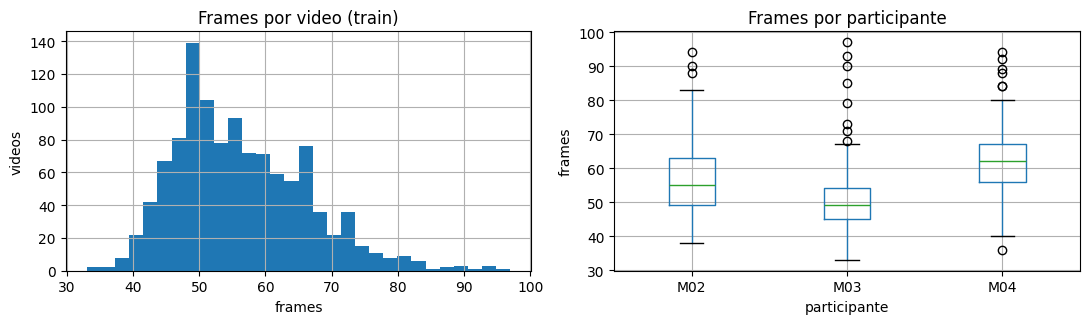

In [9]:
print(df_train["frames"].describe(percentiles=[.05, .25, .5, .75, .95]).round(1).to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df_train["frames"].hist(bins=30, ax=ax[0])
ax[0].set(title="Frames por video (train)", xlabel="frames", ylabel="videos")
df_train.boxplot(column="frames", by="participante", ax=ax[1])
ax[1].set(title="Frames por participante", xlabel="participante", ylabel="frames")
plt.suptitle("")
plt.tight_layout()
Path("../reports/figures").mkdir(parents=True, exist_ok=True)
plt.savefig("../reports/figures/paso1_frames.png", dpi=150)
plt.show()

In [10]:
# Longitud por clase y por vista, por si hay diferencias sistemáticas
print(df_train.groupby("clase")["frames"].agg(["min", "median", "max"]).to_string())
print()
print(df_train.groupby("vista")["frames"].agg(["min", "median", "max"]).to_string())

         min  median  max
clase                    
sign_01   40    54.0   84
sign_02   45    64.0   94
sign_03   35    55.0   94
sign_04   39    55.0   97
sign_05   33    50.0   73

       min  median  max
vista                  
V01     38    57.0   97
V02     35    54.0   94
V03     33    53.0   78


### 1.4 ¿Cada video tiene su landmarks?

In [14]:
def stems(lista):
    return {p.stem for p in lista}

s_lm, s_vd = stems(lm_train), stems(vd_train)
print("train = landmarks sin video:", len(s_lm - s_vd), "- videos sin landmarks:", len(s_vd - s_lm))

t_lm, t_vd = stems(lm_test), stems(vd_test)
print("test  = landmarks sin video:", len(t_lm - t_vd), "- videos sin landmarks:", len(t_vd - t_lm))

train = landmarks sin video: 0 - videos sin landmarks: 0
test  = landmarks sin video: 0 - videos sin landmarks: 0


### 1.5 ¿Cuadra con la guía? (225 por clase, 125 por participante y vista)

In [15]:
print(df_train["clase"].value_counts().sort_index().to_string())
print()
print(pd.crosstab(df_train["participante"], df_train["vista"]))
print()
print(pd.crosstab(df_train["participante"], df_train["clase"]))
print("\nParticipantes en train:", sorted(df_train["participante"].unique()))

clase
sign_01    225
sign_02    225
sign_03    225
sign_04    225
sign_05    225

vista         V01  V02  V03
participante               
M02           125  125  125
M03           125  125  125
M04           125  125  125

clase         sign_01  sign_02  sign_03  sign_04  sign_05
participante                                             
M02                75       75       75       75       75
M03                75       75       75       75       75
M04                75       75       75       75       75

Participantes en train: ['M02', 'M03', 'M04']


### Notas del paso 1

- **Conteos:** 1125 `.npy` y 1125 `.mp4` en train, con cada video emparejado con su landmarks. Cuadran con la guía.
- **Formato:** cada `.npy` es `(n_frames, 1662)` en `float64`, sin NaN y sin archivos en cero.
- **Longitud:** los videos duran entre 33 y 97 frames (mediana 55, 90 % central entre 43 y 74). `sign_02` es la más larga (mediana 64) y `sign_05` la más corta (mediana 50). La vista casi no afecta la longitud.
- **Balance:** 225 videos por clase, 125 por participante y vista, 75 por participante y clase.
- **Participantes en train:** M02, M03 y M04. El del test es M01.

## 2. Porcentaje de frames sin mano detectada (ceros) por participante y por vista

### 2.1 Verificar el orden de columnas y medir ceros por bloque
Se divide cada frame en pose, rostro, mano izquierda y mano derecha, y se mide qué fracción de frames está en cero en cada bloque. Si la pose sale en 0 %, el orden de columnas es el esperado.

In [21]:
BLOQUES = {
    "pose": slice(0, 132),
    "rostro": slice(132, 1536),
    "mano_izq": slice(1536, 1599),
    "mano_der": slice(1599, 1662),
}

def ceros_por_bloque(ruta):
    x = np.load(ruta)
    sin = {nombre: (x[:, s] == 0).all(axis=1) for nombre, s in BLOQUES.items()}
    fila = {nombre: v.mean() for nombre, v in sin.items()}
    fila["ninguna_mano"] = (sin["mano_izq"] & sin["mano_der"]).mean()
    fila["frames"] = len(x)
    return fila

filas = [ceros_por_bloque(p) for p in lm_train]
df_ceros = pd.concat(
    [df_train[["archivo", "clase", "participante", "vista"]], pd.DataFrame(filas)],
    axis=1,
)

# Fracción de frames en cero por bloque (0 = siempre detectado, 1 = nunca)
df_ceros[["pose", "rostro", "mano_izq", "mano_der", "ninguna_mano"]].describe().round(3)

,pose,rostro,mano_izq,mano_der,ninguna_mano
count,1125.000,1125.000,1125.000,1125.000,1125.000
mean,0.000,0.011,0.623,0.524,0.368
std,0.000,0.045,0.305,0.264,0.144
min,0.000,0.000,0.000,0.000,0.000
25%,0.000,0.000,0.408,0.360,0.311
50%,0.000,0.000,0.545,0.473,0.400
75%,0.000,0.000,1.000,0.642,0.467
max,0.011,0.391,1.000,1.000,0.681


### 2.2 Ceros por participante y por vista
Porcentaje de frames sin mano detectada, separado por participante y vista. Cuanto más rojo el mapa, más frames sin detección.

mano_izq  mano_der  ninguna_mano
participante vista                                  
M02          V01        36.4      80.6          36.0
             V02        43.4      79.4          41.8
             V03        45.2      82.7          42.5
M03          V01        59.9      38.7          28.2
             V02        85.7      31.8          30.2
             V03        75.2      49.6          46.9
M04          V01        81.3      39.9          38.4
             V02        63.8      31.4          30.8
             V03        70.0      37.7          36.4

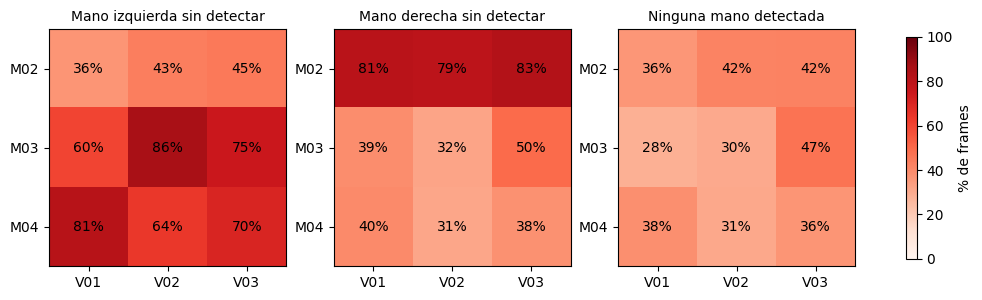

In [18]:
tabla = (df_ceros.groupby(["participante", "vista"])[["mano_izq", "mano_der", "ninguna_mano"]].mean() * 100).round(1)
display(tabla)

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col, tit in zip(
    axs,
    ["mano_izq", "mano_der", "ninguna_mano"],
    ["Mano izquierda sin detectar", "Mano derecha sin detectar", "Ninguna mano detectada"],
):
    m = df_ceros.pivot_table(index="participante", columns="vista", values=col, aggfunc="mean") * 100
    im = ax.imshow(m.values, vmin=0, vmax=100, cmap="Reds")
    ax.set_xticks(range(m.shape[1]), m.columns)
    ax.set_yticks(range(m.shape[0]), m.index)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, f"{m.values[i, j]:.0f}%", ha="center", va="center")
    ax.set_title(tit, fontsize=10)
fig.colorbar(im, ax=axs, shrink=0.8, label="% de frames")
plt.savefig("../reports/figures/paso2_ceros.png", dpi=150, bbox_inches="tight")
plt.show()

### 2.3 ¿Cuándo faltan las manos? 
Porcentaje de frames sin ninguna mano a lo largo del video (0 % es el inicio y 100 % el final), por clase. Sirve para distinguir manos en reposo de fallos de detección durante la seña.

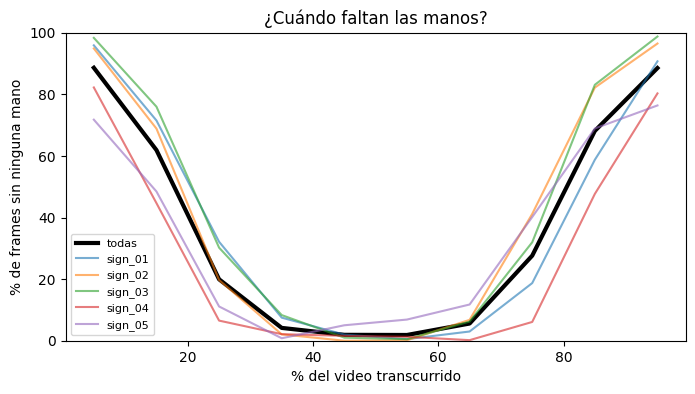

In [19]:
def perfil_temporal(ruta, bins=10):
    x = np.load(ruta)
    ninguna = ((x[:, BLOQUES["mano_izq"]] == 0).all(axis=1) &
                (x[:, BLOQUES["mano_der"]] == 0).all(axis=1)).astype(float)
    idx = np.linspace(0, len(ninguna), bins + 1).astype(int)
    return [ninguna[idx[i]:idx[i + 1]].mean() for i in range(bins)]

perfiles = pd.DataFrame([perfil_temporal(p) for p in lm_train])
perfiles["clase"] = df_train["clase"].values

x_pct = np.arange(10) * 10 + 5
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x_pct, perfiles.drop(columns="clase").mean().values * 100, "k-", lw=3, label="todas")
for c, g in perfiles.groupby("clase"):
    ax.plot(x_pct, g.drop(columns="clase").mean().values * 100, alpha=0.6, label=c)
ax.set(xlabel="% del video transcurrido", ylabel="% de frames sin ninguna mano",
        title="¿Cuándo faltan las manos?", ylim=(0, 100))
ax.legend(fontsize=8)
plt.savefig("../reports/figures/paso2_perfil_temporal.png", dpi=150, bbox_inches="tight")
plt.show()

### 2.4 Longitud del tramo con manos
Frames entre la primera y la última detección de mano (con 2 frames de margen). Es la longitud real de la seña, sin el reposo del inicio y del final.

In [30]:
def tramo_activo(ruta, margen=2):
    x = np.load(ruta)
    hay_mano = ~((x[:, BLOQUES["mano_izq"]] == 0).all(axis=1) &
                (x[:, BLOQUES["mano_der"]] == 0).all(axis=1))
    idx = np.where(hay_mano)[0]
    if len(idx) == 0:
        return pd.Series({"ini": np.nan, "fin": np.nan, "frames_utiles": 0})
    ini = max(idx[0] - margen, 0)
    fin = min(idx[-1] + margen + 1, len(x))
    return pd.Series({"ini": ini, "fin": fin, "frames_utiles": fin - ini})

activo = pd.DataFrame([tramo_activo(p) for p in lm_train])
df_ceros = pd.concat(
    [df_ceros.drop(columns=["ini", "fin", "frames_utiles"], errors="ignore"), activo],
    axis=1,
)

print("Videos sin ninguna mano:", int((df_ceros["frames_utiles"] == 0).sum()))
print(df_ceros["frames_utiles"].describe(percentiles=[.05, .5, .95]).round(1).to_string())
print()
print(df_ceros.groupby("clase")["frames_utiles"].median().to_string())

Videos sin ninguna mano: 0
count    1125.0
mean       39.7
std         8.5
min        20.0
5%         28.0
50%        39.0
95%        54.0
max        89.0

clase
sign_01    38.0
sign_02    40.0
sign_03    36.0
sign_04    42.0
sign_05    36.0


### Notas del paso 2

- **Estructura de columnas coherente con la guía:** la pose tiene 0 % de ceros (siempre detectada), el rostro casi nunca falta y las manos sí desaparecen, como se espera. 
- **Pose y rostro:** casi siempre detectados (rostro: 1,1 % de ceros en promedio, con algunos videos hasta 39 %).
- **Manos:** en promedio, 62 % de los frames sin mano izquierda y 52 % sin mano derecha. Entre 28 % y 47 % de los frames, según participante y vista, no tienen ninguna mano.
- **Diferencia por participante:** M02 tiene casi toda la actividad en la mano izquierda (derecha con ~80 % de ceros); M03 y M04, en la derecha (izquierda con 60 a 86 % de ceros). Por vista no hay un patrón consistente. Hipótesis: M02 es zurdo y M03 y M04 diestros (a confirmar en el paso 3).
- **Perfil temporal:** los ceros se concentran en el primer ~25 % y en el último ~25 a 30 % del video, cuando las manos descansan. Durante la seña (30 a 70 %) las manos se detectan casi siempre (<10 % de ceros). Las 5 clases siguen el mismo patrón.
- **Conclusión:** los ceros son sobre todo reposo y no fallos de detección durante la seña.
- **Tramo útil:** ningún video está sin manos. El tramo entre la primera y la última detección tiene una mediana de 39 frames (90 % central entre 28 y 54), frente a 55 del video completo. Por clase, la mediana va de 36 a 42 frames. Hay pocos videos largos (máx. 89) por revisar.

## 3. Mano dominante de cada participante

### 3.1 Mano dominante: qué mano se detecta y se mueve más
Para cada video se mide cuánto se desplaza el centro de cada mano entre frames consecutivos (en coordenadas normalizadas de la imagen). La mano dominante es la que se detecta más veces y se mueve más.

In [22]:
def movimiento_mano(x, inicio):
    mano = x[:, inicio:inicio + 63].reshape(len(x), 21, 3)
    det = ~(mano == 0).all(axis=(1, 2))
    centro = mano[:, :, :2].mean(axis=1)
    ok = det[1:] & det[:-1]
    paso = np.linalg.norm(np.diff(centro, axis=0), axis=1)
    return paso[ok].sum()

def metricas_mano(ruta):
    x = np.load(ruta)
    return {"mov_izq": movimiento_mano(x, 1536), "mov_der": movimiento_mano(x, 1599)}

mov = pd.DataFrame([metricas_mano(p) for p in lm_train])
df_mano = pd.concat(
    [df_ceros[["archivo", "clase", "participante", "vista", "mano_izq", "mano_der"]], mov],
    axis=1,
)
df_mano["det_izq"] = 1 - df_mano["mano_izq"]
df_mano["det_der"] = 1 - df_mano["mano_der"]
df_mano["mas_activa"] = np.where(df_mano["mov_der"] > df_mano["mov_izq"], "derecha", "izquierda")

resumen = df_mano.groupby("participante")[["det_izq", "det_der", "mov_izq", "mov_der"]].mean().round(3)
display(resumen)
print("\nFracción de videos donde cada mano es la más activa:")
display(pd.crosstab(df_mano["participante"], df_mano["mas_activa"], normalize="index").round(2))

,det_izq,det_der,mov_izq,mov_der
participante,,,,
M02,0.583,0.191,1.072,0.271
M03,0.264,0.600,0.229,0.948
M04,0.283,0.637,0.243,1.183



Fracción de videos donde cada mano es la más activa:


mas_activa,derecha,izquierda
participante,,
M02,0.00,1.00
M03,0.98,0.02
M04,0.94,0.06


### 3.2 Mano más activa por participante y por seña
Si una seña se hace con las dos manos, el reparto será parejo; si se hace con una sola, se verá claramente cuál.

In [23]:
display(
    pd.crosstab([df_mano["participante"], df_mano["clase"]], df_mano["mas_activa"], normalize="index").round(2)
)

mas_activa            derecha  izquierda
participante clase                      
M02          sign_01     0.00       1.00
             sign_02     0.00       1.00
             sign_03     0.00       1.00
             sign_04     0.00       1.00
             sign_05     0.00       1.00
M03          sign_01     1.00       0.00
             sign_02     0.93       0.07
             sign_03     1.00       0.00
             sign_04     0.95       0.05
             sign_05     1.00       0.00
M04          sign_01     1.00       0.00
             sign_02     1.00       0.00
             sign_03     1.00       0.00
             sign_04     0.72       0.28
             sign_05     1.00       0.00

### 3.3 Comprobación: ¿"mano izquierda" y "mano derecha" están intercambiadas?
Se compara la muñeca de cada mano con las muñecas de la pose (puntos 15 y 16). Si las etiquetas son consistentes, la mano izquierda debería estar mucho más cerca de la muñeca izquierda de la pose.

In [24]:
def dist_muneca(ruta):
    x = np.load(ruta)
    r = {}
    for nombre, hc in [("izq", 1536), ("der", 1599)]:
        det = ~(x[:, hc:hc + 63] == 0).all(axis=1)
        if det.sum() == 0:
            r.update({f"{nombre}_a_pose_izq": np.nan, f"{nombre}_a_pose_der": np.nan})
            continue
        m = x[det, hc:hc + 2]
        r[f"{nombre}_a_pose_izq"] = np.linalg.norm(m - x[det, 60:62], axis=1).mean()
        r[f"{nombre}_a_pose_der"] = np.linalg.norm(m - x[det, 64:66], axis=1).mean()
    return r

dist = pd.DataFrame([dist_muneca(p) for p in lm_train])
dist["participante"] = df_train["participante"].values
display(dist.groupby("participante").mean().round(3))

,izq_a_pose_izq,izq_a_pose_der,der_a_pose_izq,der_a_pose_der
participante,,,,
M02,0.015,0.418,0.170,0.041
M03,0.019,0.247,0.423,0.017
M04,0.026,0.193,0.467,0.016


### Notas del paso 3

- **Mano dominante confirmada:** M02 es zurdo (mano izquierda más activa en el 100 % de sus videos; movimiento 1,07 frente a 0,27). M03 y M04 son diestros (98 % y 94 % de sus videos; movimiento 0,95 y 1,18 frente a 0,23 y 0,24).
- **Consistente por seña:** M02 usa la izquierda en las 5 señas. En M03 y M04 la derecha domina en todas, con una excepción: `sign_04` de M04 (72 % derecha, 28 % izquierda), por revisar en el paso 4.
- **Etiquetas izquierda/derecha consistentes:** cada mano está a ~0,02 de su muñeca correspondiente en la pose y a 0,19 a 0,47 de la opuesta, así que no hay etiquetas intercambiadas.
- **Criterio automático:** "la mano con más movimiento es la dominante" coincide con el participante en ~97 % de los videos; no requiere etiquetas y se puede aplicar a cada video del test.
- **Riesgo para la validación:** en el fold que valida con M02, el modelo entrena solo con diestros; sin reflejado, ese fold medirá cambio de mano y no generalización de seña.

## 4. Las 5 señas y qué partes del cuerpo usa cada una

### 4.1 ¿Qué usa cada seña? Descriptores desde los landmarks

In [31]:
base = pd.concat(
    [df_ceros[["archivo", "clase", "participante", "vista", "ini", "fin"]], df_mano["mas_activa"]],
    axis=1,
)
base.head()

,archivo,clase,participante,vista,ini,fin,mas_activa
0,S01_M02_V01_C01_Clip076.npy,sign_01,M02,V01,4,52,izquierda
1,S01_M02_V01_C01_Clip077.npy,sign_01,M02,V01,15,68,izquierda
2,S01_M02_V01_C01_Clip078.npy,sign_01,M02,V01,9,63,izquierda
3,S01_M02_V01_C01_Clip079.npy,sign_01,M02,V01,9,65,izquierda
4,S01_M02_V01_C01_Clip080.npy,sign_01,M02,V01,13,67,izquierda


### 4.2 Función de descriptores
Para un video, mide dónde está la mano dominante respecto a los hombros, cuánto se mueve, cuánto participa la otra mano y cuánto cambia la forma de los dedos.

In [32]:
def centro_rel(mano, signo, medio, ancho):
    # Centro de la mano = promedio de sus 21 puntos (solo x, y).
    # Se resta el centro de los hombros y se divide por el ancho de hombros:
    # así 1,0 significa "a un ancho de hombro de distancia", sin importar
    # qué tan cerca esté la persona de la cámara.
    c = (mano[:, :, :2].mean(axis=1) - medio) / ancho[:, None]
    c[:, 0] *= signo          # si es zurdo, se refleja el eje horizontal
    return c

def largo_camino(c, det):
    # Distancia total que recorre el centro de la mano, sumando los pasos
    # entre frames consecutivos (solo cuando la mano se ve en los dos).
    ok = det[1:] & det[:-1]
    return np.linalg.norm(np.diff(c, axis=0), axis=1)[ok].sum()

def descriptores_y_trayectoria(ruta, ini, fin, dom_izq, n_t=20):
    x = np.load(ruta)[int(ini):int(fin)]          # solo el tramo con manos

    # Cada fila tiene 63 valores por mano -> se reordenan como 21 puntos x (x, y, z)
    izq = x[:, 1536:1599].reshape(-1, 21, 3)
    der = x[:, 1599:1662].reshape(-1, 21, 3)
    dom, nodom = (izq, der) if dom_izq else (der, izq)

    # Pose: 33 puntos x (x, y, z, visibilidad). Puntos 11 y 12 = hombros, 0 = nariz.
    pose = x[:, :132].reshape(-1, 33, 4)
    medio = (pose[:, 11, :2] + pose[:, 12, :2]) / 2
    ancho = np.linalg.norm(pose[:, 11, :2] - pose[:, 12, :2], axis=1)
    ancho = np.where(ancho < 1e-3, np.nan, ancho)
    ok_pose = ~np.isnan(ancho)

    # Frames donde cada mano se ve (no todo en cero)
    det_d = ~(dom == 0).all(axis=(1, 2)) & ok_pose
    det_n = ~(nodom == 0).all(axis=(1, 2)) & ok_pose
    if det_d.sum() < 3:
        return None, None

    signo = -1 if dom_izq else 1
    c_d = centro_rel(dom, signo, medio, ancho)
    c_n = centro_rel(nodom, signo, medio, ancho)
    cd = c_d[det_d]

    # Distancia de la mano a la nariz, en anchos de hombro
    nariz = pose[:, 0, :2]
    dist_cara = np.linalg.norm(dom[:, :, :2].mean(axis=1) - nariz, axis=1) / ancho

    # Cambio de forma de los dedos: se coloca la muñeca en el origen y se escala
    # por el tamaño de la mano; luego se mide cuánto varía cada punto en el tiempo.
    pts = dom[det_d][:, :, :2]
    pts = pts - pts[:, 0:1]
    escala = np.linalg.norm(dom[det_d][:, 9, :2] - dom[det_d][:, 0, :2], axis=1)
    escala = np.where(escala < 1e-6, np.nan, escala)
    forma = np.nanmean((pts / escala[:, None, None]).std(axis=0))

    mov_d = largo_camino(c_d, det_d)
    mov_n = largo_camino(c_n, det_n)

    # Trayectoria: la posición de la mano en 20 momentos equiespaciados
    idx = np.where(det_d)[0]
    tt = np.linspace(idx[0], idx[-1], n_t)
    tray = np.c_[np.interp(tt, idx, cd[:, 0]), np.interp(tt, idx, cd[:, 1])]

    desc = {
        "x_med": np.median(cd[:, 0]), "y_med": np.median(cd[:, 1]),
        "rango_x": np.ptp(cd[:, 0]), "rango_y": np.ptp(cd[:, 1]),
        "dist_cara": np.nanmedian(dist_cara[det_d]),
        "mov_dom": mov_d, "mov_nodom": mov_n,
        "ratio_mov": mov_n / (mov_d + 1e-9),
        "det_nodom": det_n.sum() / max(len(x), 1),
        "forma_mano": forma,
    }
    return desc, tray

### 4.3 Descriptores por seña
Mediana de cada descriptor sobre los 225 videos de cada seña.

In [33]:
desc, trays = [], []
for p, f in zip(lm_train, base.itertuples()):
    d_, t_ = descriptores_y_trayectoria(p, f.ini, f.fin, f.mas_activa == "izquierda")
    desc.append(d_ if d_ is not None else {})
    trays.append(t_ if t_ is not None else np.full((20, 2), np.nan))
trays = np.array(trays)

df_desc = pd.concat([base[["archivo", "clase", "participante", "vista"]], pd.DataFrame(desc)], axis=1)

cols = ["y_med", "x_med", "dist_cara", "rango_y", "rango_x", "mov_dom", "ratio_mov", "det_nodom", "forma_mano"]
df_desc.groupby("clase")[cols].median().round(2)

,y_med,x_med,dist_cara,rango_y,rango_x,mov_dom,ratio_mov,det_nodom,forma_mano
clase,,,,,,,,,
sign_01,-0.71,-0.35,0.47,2.97,0.56,5.52,0.00,0.00,0.57
sign_02,0.27,-0.23,1.54,2.54,0.34,5.50,0.47,0.85,0.57
sign_03,-1.09,-0.45,0.61,3.29,0.71,6.05,0.00,0.00,0.52
sign_04,0.93,-0.50,2.14,2.03,0.34,4.58,0.56,0.47,0.61
sign_05,0.74,-0.11,1.79,1.81,0.75,3.70,0.10,0.19,0.43


**Cómo leer la tabla** (cada valor es la mediana de los 225 videos de esa seña)

| Columna | Qué significa | Cómo leerla |
|---|---|---|
| `y_med` | Altura de la mano dominante respecto a los hombros | Negativo: por encima de los hombros (zona de la cara). Cerca de 0: a la altura de los hombros. Positivo: hacia el pecho o más abajo |
| `x_med` | Posición lateral respecto al centro del cuerpo | Comparable entre personas, porque se reflejó el eje en los zurdos |
| `dist_cara` | Distancia de la mano a la nariz, en anchos de hombro | Valores pequeños: mano cerca de la cara |
| `rango_y`, `rango_x` | Cuánto recorre la mano en vertical y en horizontal | Alto: movimiento amplio |
| `mov_dom` | Recorrido total de la mano dominante | Alto: seña con mucho movimiento |
| `ratio_mov` | Movimiento de la otra mano ÷ el de la dominante | Cerca de 0: la otra mano está quieta. Cerca de 1: las dos se mueven (seña bimanual) |
| `det_nodom` | Fracción de frames en que se ve la otra mano | Alto: la otra mano está en cuadro |
| `forma_mano` | Cuánto cambian los dedos durante la seña | Alto: cambia la configuración de la mano. Bajo: mantiene la forma y solo se mueve |

### 4.4 Trayectoria de la mano dominante por seña y participante
Posición media de la mano a lo largo de la seña (20 puntos en el tiempo), respecto al hombro. El punto marca el inicio.

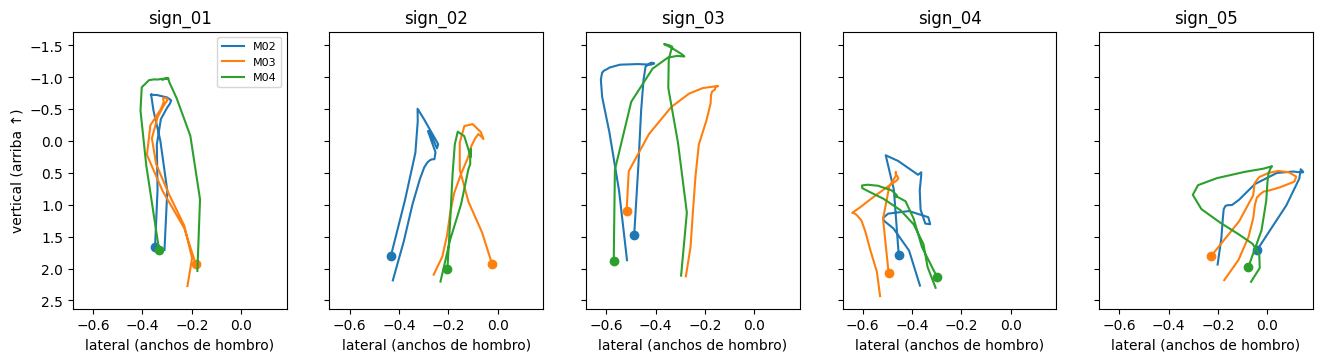

In [39]:
fig, axs = plt.subplots(1, 5, figsize=(16, 3.6), sharex=True, sharey=True)
for ax, c in zip(axs, sorted(df_desc["clase"].unique())):
    for part in sorted(df_desc["participante"].unique()):
        m = ((df_desc["clase"] == c) & (df_desc["participante"] == part)).values
        tr = np.nanmean(trays[m], axis=0)
        linea, = ax.plot(tr[:, 0], tr[:, 1], label=part)
        ax.plot(tr[0, 0], tr[0, 1], "o", color=linea.get_color())
    ax.invert_yaxis()
    ax.set_title(c)
    ax.set_xlabel("lateral (anchos de hombro)")
axs[0].set_ylabel("vertical (arriba ↑)")
axs[0].legend(fontsize=8)
plt.savefig("../reports/figures/paso4_trayectorias.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.5 Fotogramas de cada seña
Cuatro fotogramas del tramo con manos de un video por seña, para ponerle nombre a lo que muestran los números.

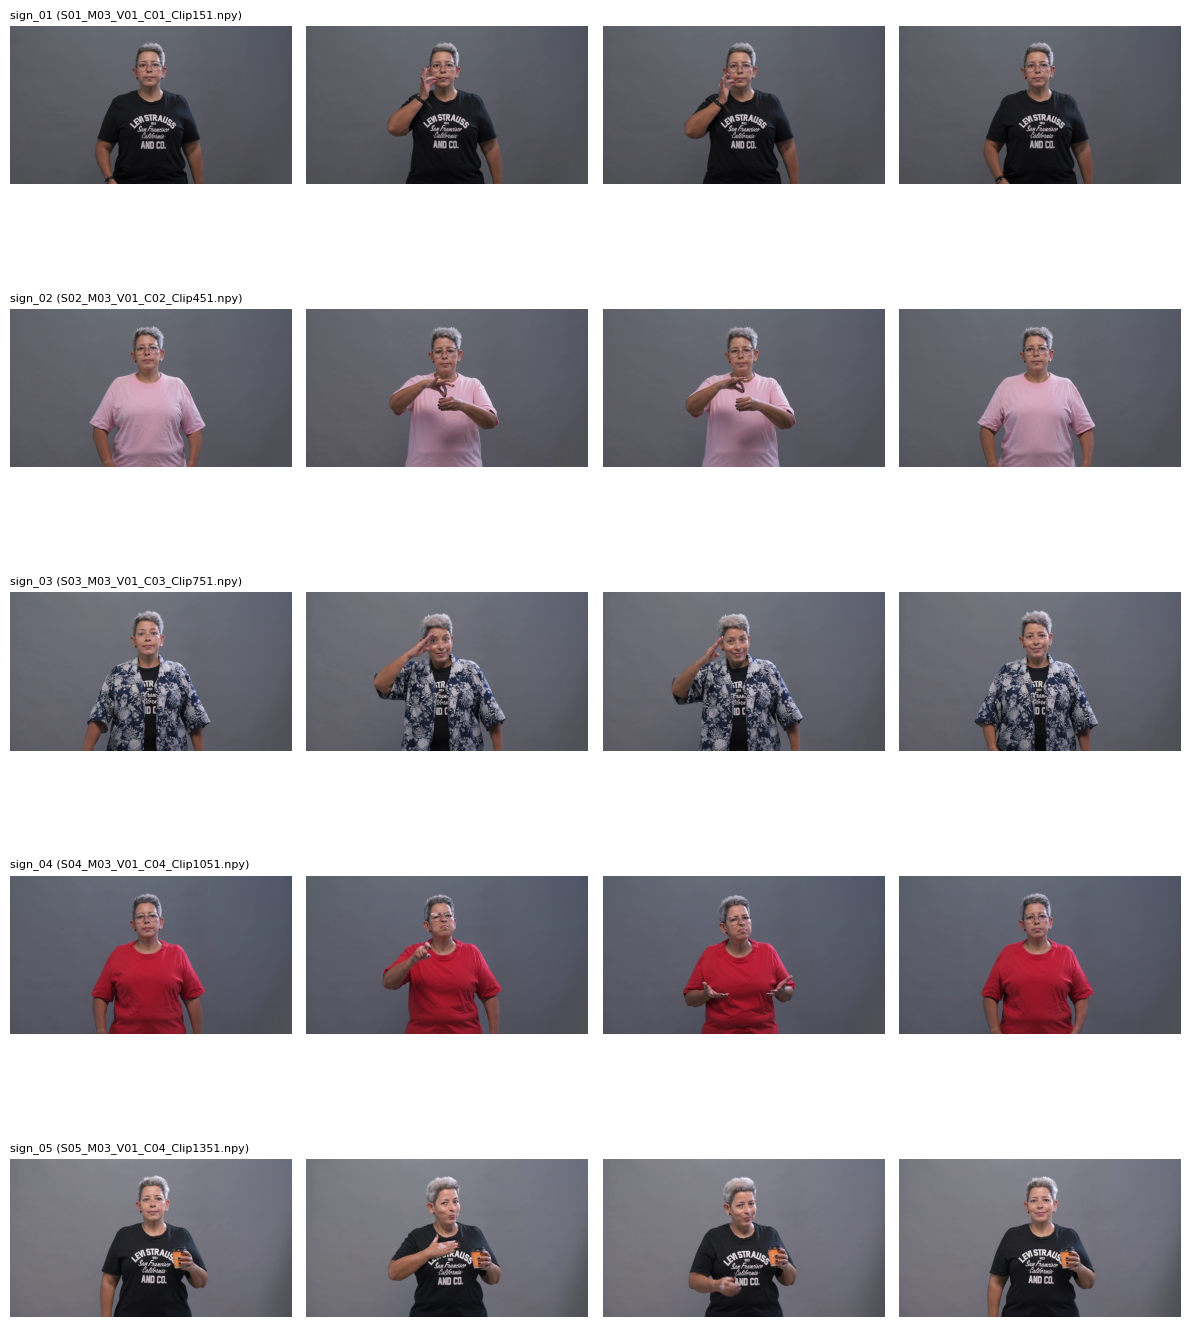

In [41]:
# Esta celda necesita los videos .mp4 en data/train/videos y OpenCV (pip install opencv-python).
# Si no están disponibles, se omite sin detener el notebook.
try:
    import cv2
except ImportError:
    cv2 = None

if cv2 is None or not (TRAIN / "videos").exists():
    print("Se omite 4.5: faltan los videos en data/train/videos o el paquete opencv-python.")
else:
    def frame_de_video(ruta_video, idx):
        cap = cv2.VideoCapture(str(ruta_video))
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
        ok, fr = cap.read()
        cap.release()
        return cv2.cvtColor(fr, cv2.COLOR_BGR2RGB) if ok else None

    PART, VISTA = "M03", "V01"   # cambia estos dos valores para ver otros
    clases = sorted(base["clase"].unique())
    fig, axs = plt.subplots(len(clases), 4, figsize=(12, 3 * len(clases)))
    for i, c in enumerate(clases):
        fila = base[(base["clase"] == c) & (base["participante"] == PART) & (base["vista"] == VISTA)].iloc[0]
        ruta_v = TRAIN / "videos" / c / (Path(fila["archivo"]).stem + ".mp4")
        for j, idx in enumerate(np.linspace(fila["ini"], fila["fin"] - 1, 4).astype(int)):
            fr = frame_de_video(ruta_v, idx)
            axs[i, j].axis("off")
            if fr is not None:
                axs[i, j].imshow(fr)
            if j == 0:
                axs[i, j].set_title(f"{c} ({fila['archivo']})", fontsize=8, loc="left")
    plt.tight_layout()
    plt.savefig("../reports/figures/paso4_fotogramas.png", dpi=120, bbox_inches="tight")
    plt.show()

### 4.6 Casos por revisar
`sign_04` de M04 (¿usa las dos manos?) y videos con más de 60 frames útiles.

In [38]:
print("sign_04 de M04, ordenados por cuánto se mueve la otra mano:")
display(
    df_desc[(df_desc["participante"] == "M04") & (df_desc["clase"] == "sign_04")]
    .sort_values("ratio_mov", ascending=False)[["archivo", "mov_dom", "mov_nodom", "ratio_mov"]]
    .head(10)
    .round(2)
)

print("\nVideos con más de 60 frames útiles:")
display(df_ceros[df_ceros["frames_utiles"] > 60][["archivo", "frames", "frames_utiles", "ini", "fin"]])

sign_04 de M04, ordenados por cuánto se mueve la otra mano:


,archivo,mov_dom,mov_nodom,ratio_mov
899,S04_M04_V03_C04_Clip1200.npy,4.71,5.23,1.11
837,S04_M04_V01_C04_Clip1138.npy,2.87,2.91,1.01
835,S04_M04_V01_C04_Clip1136.npy,2.96,2.94,0.99
881,S04_M04_V03_C04_Clip1182.npy,4.58,4.49,0.98
878,S04_M04_V03_C04_Clip1179.npy,6.13,6.01,0.98
895,S04_M04_V03_C04_Clip1196.npy,4.85,4.73,0.97
845,S04_M04_V01_C04_Clip1146.npy,3.37,3.28,0.97
828,S04_M04_V01_C04_Clip1129.npy,2.86,2.72,0.95
846,S04_M04_V01_C04_Clip1147.npy,3.39,3.21,0.95
879,S04_M04_V03_C04_Clip1180.npy,3.21,3.03,0.94



Videos con más de 60 frames útiles:


,archivo,frames,frames_utiles,ini,fin
325,S02_M03_V02_C02_Clip476.npy,65,62,3,65
339,S02_M03_V02_C02_Clip490.npy,68,62,0,62
344,S02_M03_V02_C02_Clip495.npy,66,66,0,66
550,S03_M03_V02_C03_Clip776.npy,85,77,0,77
759,S04_M03_V01_C04_Clip1060.npy,90,88,0,88
760,S04_M03_V01_C04_Clip1061.npy,93,89,2,91
761,S04_M03_V01_C04_Clip1062.npy,97,89,2,91
762,S04_M03_V01_C04_Clip1063.npy,79,79,0,79
875,S04_M04_V03_C04_Clip1176.npy,64,64,0,64
877,S04_M04_V03_C04_Clip1178.npy,63,63,0,63


### Notas del paso 4

- **Las señas se separan por altura y por manos.** Café (`sign_01`) y Hola (`sign_03`) son de una sola mano, arriba y cerca de la cara (`y_med` -0,71 y -1,09; `dist_cara` 0,47 y 0,61). Aromática (`sign_02`) usa las dos manos a la altura del pecho (otra mano visible en 85 % de los frames; `ratio_mov` 0,47). Qué necesitas (`sign_04`) usa las dos manos, abajo y lejos de la cara (`y_med` 0,93; `dist_cara` 2,14; otra mano visible en 47 %). Con gusto (`sign_05`) es casi de una mano, baja y cerca del centro del cuerpo, con el menor movimiento total (3,70) y el menor cambio de forma de los dedos (0,43).
- **Pares con riesgo de confusión:** `sign_01` con `sign_03` (ambas de una mano, arriba; difieren en altura y recorrido horizontal) y `sign_04` con `sign_05` (ambas abajo; difieren sobre todo en el uso de la segunda mano).
- **Trayectorias:** todas parten del reposo (mano abajo). `sign_01`, `sign_02` y `sign_05` son consistentes entre M02, M03 y M04; `sign_03` sube alto en los tres pero con caminos laterales distintos; `sign_04` es la más irregular y la menos consistente entre personas.
- **Limitaciones:** `rango_y` y `mov_dom` incluyen subir la mano desde el reposo, así que no describen solo la seña. `forma_mano` varía poco entre señas (0,43 a 0,61) y no discrimina bien.
- **Pendiente:** fotogramas de cada seña (4.5) y revisión manual de `sign_04` de M04 y de los videos con más de 60 frames útiles (4.6).

## 5. Hallazgos del dataset LSC5 y recomendaciones de preprocesamiento


**Fase 1 (estudio del dataset)**

Alcance: conjunto de entrenamiento (1125 videos y 1125 archivos de landmarks) de los participantes M02, M03 y M04. El participante M01 es el del test y no se usó para ninguna decisión. Notebook de origen: `notebooks/01_exploracion_dataset.ipynb`. Figuras en `reports/figures/`.

### Resumen

- Los datos están completos, balanceados y sin valores corruptos: 225 videos por seña, 125 por participante y vista.
- Casi un tercio de cada video es reposo sin manos. La seña ocurre en el tramo central (mediana de 39 frames, frente a 55 del video completo).
- Hay un participante zurdo (M02) y dos diestros (M03, M04). Sin corregirlo, la validación que deja a M02 fuera mediría el cambio de mano y no la generalización de la seña.
- Las señas se distinguen por la altura de la mano respecto a los hombros y por si participa la segunda mano. Los pares con más riesgo de confusión son `sign_01`/`sign_03` y `sign_04`/`sign_05`.
- Los participantes difieren en ritmo (mediana de 49 a 62 frames por video), así que la longitud no debe ser una pista para el modelo.

### 1. Estructura y calidad de los datos

- **Conteos:** 1125 `.npy` y 1125 `.mp4` en train, cada video emparejado con su landmarks. Coinciden con la guía.
- **Formato:** cada `.npy` es `(n_frames, 1662)` en `float64`, sin NaN y sin archivos completamente en cero.
- **Balance:** 225 videos por seña, 125 por participante y vista, 75 por participante y seña.
- **Participantes:** M02, M03 y M04 en train; M01 es el del test.
- **Longitud:** entre 33 y 97 frames (mediana 55; 90 % central entre 43 y 74). `sign_02` es la más larga (mediana 64) y `sign_05` la más corta (mediana 50); las otras tres rondan 54 a 55. La vista casi no afecta la longitud.
- **Ritmo por participante:** M03 es el más rápido (mediana ~49 frames), M02 intermedio (~55) y M04 el más lento (~62), con cajas casi sin solapamiento entre M03 y M04. Los tres tienen videos atípicos largos (hasta 97 frames).

### 2. Ausencia de manos (ceros)

- **Estructura de columnas coherente con la guía:** la pose tiene 0 % de ceros, el rostro casi nunca falta (1,1 % en promedio; máximo 39 % en un video) y las manos sí desaparecen, como se espera.
- **Manos:** en promedio, 62 % de los frames sin mano izquierda y 52 % sin mano derecha. Entre 28 % y 47 % de los frames, según participante y vista, no tienen ninguna mano. Por vista no hay un patrón consistente.
- **Perfil temporal:** los ceros se concentran en el primer ~25 % y en el último ~25 a 30 % del video (manos en reposo). Durante la seña (30 a 70 % del video) las manos se detectan casi siempre (menos de 10 % de ceros). Las cinco señas siguen el mismo patrón. Los ceros son reposo y no fallos de detección durante la seña.
- **Tramo útil** (entre la primera y la última mano detectada, con 2 frames de margen): mediana de 39 frames (90 % central entre 28 y 54; máximo 89). Por seña, la mediana va de 36 a 42. Ningún video está sin manos.

## 3. Mano dominante

| Participante | Mano más activa | Videos donde lo es | Movimiento (izq. / der.) |
|---|---|---|---|
| M02 | Izquierda | 100 % | 1,07 / 0,27 |
| M03 | Derecha | 98 % | 0,23 / 0,95 |
| M04 | Derecha | 94 % | 0,24 / 1,18 |

- La preferencia es estable en las cinco señas. La única excepción visible es `sign_04` de M04 (72 % derecha, 28 % izquierda), pendiente de revisión manual.
- **Etiquetas consistentes:** cada mano está a ~0,02 de su muñeca correspondiente en la pose y a 0,19 a 0,47 de la opuesta, así que "izquierda" y "derecha" no están intercambiadas.
- **Criterio automático:** "la mano con más desplazamiento es la dominante" coincide con el participante en 94 % a 100 % de los videos y no necesita etiquetas, de modo que se puede aplicar a cada video del test.
- La mano dominante de M01 (test) es desconocida.

### 4. Las cinco señas

Medianas sobre los 225 videos de cada seña. Altura respecto a los hombros en anchos de hombro (negativo = por encima).

| Seña | Altura (`y_med`) | Distancia a la cara | Segunda mano | Cambio de forma de dedos |
|---|---|---|---|---|
| `sign_01` Café | -0,71 | 0,47 | No participa | 0,57 |
| `sign_02` Aromática | 0,27 | 1,54 | Sí (visible en 85 % de frames) | 0,57 |
| `sign_03` Hola | -1,09 | 0,61 | No participa | 0,52 |
| `sign_04` Qué necesitas | 0,93 | 2,14 | Sí (visible en 47 %) | 0,61 |
| `sign_05` Con gusto | 0,74 | 1,79 | Casi no (visible en 19 %) | 0,43 |

- **Qué separa a las señas:** la altura de la mano y el uso de la segunda mano. El cambio de forma de los dedos casi no discrimina (0,43 a 0,61).
- **Pares con riesgo de confusión:** `sign_01` con `sign_03` (ambas de una mano, arriba; difieren en altura y recorrido horizontal) y `sign_04` con `sign_05` (ambas abajo; difieren sobre todo en la segunda mano).
- **Consistencia entre participantes:** `sign_01`, `sign_02` y `sign_05` son consistentes; `sign_03` sube alto en los tres pero con caminos laterales distintos; `sign_04` es la más irregular.
- **Limitación:** el rango vertical y el movimiento total incluyen subir la mano desde el reposo, por lo que no describen solo la seña.

### 5. Recomendaciones de preprocesamiento

**Datos y formato**

1. Convertir de `float64` a `float32`: ocupa la mitad de memoria y es lo habitual en redes neuronales.
2. Recortar cada video al tramo entre la primera y la última mano detectada, con unos 2 frames de margen. Conviene exigir una detección sostenida de varios frames, para que una mano que asoma un instante no estire el tramo (ver pendientes).
3. Fijar la longitud a partir de los frames útiles (mediana ~39): propuesta de remuestrear a ~40 frames. Es una propuesta que hay que validar entrenando.
4. No tratar los ceros como coordenadas reales: usar una máscara de datos faltantes o interpolar antes de normalizar.

**Mano dominante**

5. Reflejar los videos de mano dominante izquierda (invertir x, intercambiar las manos y los pares izquierda/derecha de la pose) para que todos queden como diestros. Decidirlo por video con el criterio de movimiento, sin etiquetas, para aplicarlo igual al test.
6. En el entrenamiento, reflejar también al azar los videos diestros, para que el modelo no dependa de qué mano se usa.

**Representación**

7. Conservar ambas manos y solo los puntos de la pose de cabeza, hombros, codos y muñecas, sin la malla de 468 puntos del rostro. La segunda mano distingue `sign_02` y `sign_04` del resto, y quitar el rostro simplifica el reflejado.
8. Normalizar respecto a los hombros (centrar en el punto medio y escalar por el ancho de hombros): la información clave es la altura relativa al cuerpo y así se compensa la distancia a la cámara.
9. Usar un modelo que vea la secuencia completa: las señas se distinguen por su trayectoria, no por una postura fija.

**Augmentation**

10. Aumentar la velocidad (acelerar y frenar los videos), porque el ritmo varía entre participantes y la duración da pistas de la seña. Añadir pequeños desplazamientos laterales y cambios de escala, porque la posición lateral varía entre personas.

**Validación**

11. Usar Leave-One-Signer-Out con M02, M03 y M04 como folds, y M01 solo para el test.
12. Calcular cualquier estadística de normalización solo con los participantes de entrenamiento de cada fold.
13. Si se hacen divisiones adicionales por ejecución, mantener juntas las tres vistas de una misma ejecución.
14. Revisar las matrices de confusión, sobre todo de `sign_04` y de los pares `sign_01`/`sign_03` y `sign_04`/`sign_05`.

### 6. Riesgos

- **Cambio de mano en la validación:** al validar con M02, el modelo entrena solo con diestros. Sin el reflejado (recomendación 5), ese fold mediría el cambio de mano y no la generalización de la seña.
- **Participante de test desconocido:** M01 puede ser diestro o zurdo, y puede tener un ritmo distinto.
- **Duración como atajo:** la longitud del video ya da pistas de la seña y del participante.
- **`sign_04`:** es la seña menos consistente entre personas y probablemente la más difícil.

### 7. Pendientes

- Revisión manual de los videos de `sign_04` de M04 donde la otra mano se mueve más, para ver si usa las dos manos.
- Revisión manual de los videos con más de 60 frames útiles, para ver si el recorte se estira por detecciones sueltas.
- Fotogramas de cada seña (celda 4.5 del notebook), para describirlas en una frase.
- Confirmar con Chile la equivalencia entre los participantes del plan y los del dataset: se supone que A, B y C corresponden a M02, M03 y M04, y D a M01.
